# ATP Tennis Match Prediction
An AI-assisted educational project for Sohan Cherukuri.

**Question:** Can rankings and prior performance improve on always picking the higher-ranked player?

Model: logistic regression. Training: 2016–2022. Validation: 2023. Final test: 2024–2025.
2014–2015 provides historical warm-up. The final test is used for reporting, not model selection.

Run all cells on a standard CPU. No paid service or API key is needed.


In [1]:
%pip -q install pandas numpy scikit-learn matplotlib


Verified installed packages: 3.1.0 2.5.4 1.9.1 3.11.2


## Data and attribution
Source: [TennisMyLife TML-Database](https://github.com/Tennismylife/TML-Database).
The source permits educational/research analysis and requests acknowledgement. Its terms prohibit commercial reuse without permission.
The database credits Jeff Sackmann's Tennis Abstract work. See the saved source README for current terms.
Raw data is downloaded from a pinned commit and verified by SHA-256. It is not republished here.


In [2]:
from pathlib import Path
import json, hashlib
from urllib.request import Request, urlopen
DATA = Path('data')
DATA.mkdir(exist_ok=True)
manifest = {'repository': 'https://github.com/Tennismylife/TML-Database', 'commit': '9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f', 'files': [{'file': '2014.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2014.csv', 'sha256': 'b702380d8fce08c48c9dfc9a2d5df06345694617fd398c252f4230c3277e65d9'}, {'file': '2015.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2015.csv', 'sha256': '36e1868c2f31fb7c58d99948b3c544dd781ba3ec9c75ff94d437637d22eef56d'}, {'file': '2016.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2016.csv', 'sha256': '28a106544a50184c742263eed43a49ca725be735cbf640143c51ab32e40e8588'}, {'file': '2017.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2017.csv', 'sha256': 'b55f12e9bf5220b694cd8954f65027f1b7e649ce4977da0316a1a3f4f2f20ea4'}, {'file': '2018.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2018.csv', 'sha256': '5abc0e80e83ddab9f04f682b6e72fa062ad11d523c88f3c105f690a555bacc4a'}, {'file': '2019.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2019.csv', 'sha256': '6821d93e92de9110b365cd3b4f8d30138c261bcf679de4a5ccaff6917c33335e'}, {'file': '2020.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2020.csv', 'sha256': '3c97228abeede853db0139e4b49699aecbadafd2e7000acaaf9a449d38da202d'}, {'file': '2021.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2021.csv', 'sha256': '80d570be31d778b143eb58380258243785bf3fcb18db144b42704bc6c56d941b'}, {'file': '2022.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2022.csv', 'sha256': 'd70036c6ee6c27dd3deda6e6c9ccd500b66e6e78106fb00794cb277e37353357'}, {'file': '2023.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2023.csv', 'sha256': '9faaf53186ef908b3322d521a8dd2a717401167c0e400a99e1efddb23e13600f'}, {'file': '2024.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2024.csv', 'sha256': 'db27fb184b62bc1716ecc84c5a8365088e34e8e9a0101a59782ec7907f6e2de8'}, {'file': '2025.csv', 'url': 'https://raw.githubusercontent.com/Tennismylife/TML-Database/9aecc242e98b41fb6a69ecfc188a58ebb4cf2f6f/2025.csv', 'sha256': 'a00f5f991b4949c2c6867637ac02a8c44b9058780da67aba8600e9140002f8d3'}]}
for item in manifest['files']:
    target = DATA / item['file']
    if not target.exists():
        request = Request(item['url'], headers={'User-Agent': 'Educational-Tennis-Project'})
        target.write_bytes(urlopen(request, timeout=60).read())
    assert hashlib.sha256(target.read_bytes()).hexdigest() == item['sha256'], 'Data snapshot mismatch'
(DATA / 'manifest.json').write_text(json.dumps(manifest, indent=2))
print('Historical data ready.')


Historical data ready.


## Load and filter historical matches

In [3]:
"""ATP match prediction. Run this script, or use the companion notebook."""
from pathlib import Path
from collections import defaultdict, deque
import hashlib
import json
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

ROOT = Path(__file__).parent if '__file__' in globals() else Path.cwd()
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
manifest = json.loads((DATA / 'manifest.json').read_text())
for item in manifest['files']:
    assert hashlib.sha256((DATA / item['file']).read_bytes()).hexdigest() == item['sha256']
raw = pd.concat([pd.read_csv(DATA / item['file']) for item in manifest['files']], ignore_index=True)
raw['date'] = pd.to_datetime(raw['tourney_date'].astype(str), format='%Y%m%d')
keys = ['tourney_id', 'match_num', 'winner_id', 'loser_id']
raw = raw.drop_duplicates(keys).sort_values(['date', 'tourney_id', 'match_num'])
# Exclude team events, incomplete matches, unknown ranks and surfaces.
levels = ['250', '500', '1000', 'G', 'F', 'A', 'M']
valid = raw['tourney_level'].astype(str).isin(levels)
valid &= raw['surface'].isin(['Hard', 'Clay', 'Grass'])
valid &= ~raw['score'].fillna('').str.contains('RET|W/O|DEF|ABN', case=False, regex=True)
valid &= raw[['winner_rank', 'loser_rank']].notna().all(axis=1)
valid &= (raw[['winner_rank', 'loser_rank']] > 0).all(axis=1)
matches = raw.loc[valid].copy()
print(f'Loaded {len(raw):,} unique rows; retained {len(matches):,} completed, ranked tour matches.')



Loaded 33,618 unique rows; retained 29,457 completed, ranked tour matches.


## Create pre-match features

In [4]:
# Tournament dates are start dates, not exact match dates. Delay ALL historical
# outcomes 21 days after tournament start, avoiding within/overlapping-event leakage.
history = defaultdict(lambda: deque(maxlen=10))
surface_history = defaultdict(lambda: [0, 0])
pending = []
rows = []
for n, match in enumerate(matches.itertuples()):
    while pending and pending[0][0] < match.date:
        _, _, winner, loser, surface = heapq.heappop(pending)
        history[winner].append(1)
        history[loser].append(0)
        surface_history[(winner, surface)][0] += 1
        surface_history[(winner, surface)][1] += 1
        surface_history[(loser, surface)][1] += 1
    # Stable random orientation prevents the winner column from becoming the label.
    key = f'{match.tourney_id}|{match.match_num}|{match.winner_id}|{match.loser_id}'
    winner_is_a = int(hashlib.sha256(key.encode()).hexdigest()[:8], 16) % 2 == 0
    a, b = (match.winner_id, match.loser_id) if winner_is_a else (match.loser_id, match.winner_id)
    rank_a, rank_b = (match.winner_rank, match.loser_rank) if winner_is_a else (match.loser_rank, match.winner_rank)
    name_a, name_b = (match.winner_name, match.loser_name) if winner_is_a else (match.loser_name, match.winner_name)
    def form(player):
        results = history[player]
        return (sum(results) + 2) / (len(results) + 4)
    def surface_rate(player):
        wins, total = surface_history[(player, match.surface)]
        return (wins + 5) / (total + 10)
    rank_signal = np.log(rank_b / rank_a)
    rows.append({'match_id': key, 'date': match.date, 'surface': match.surface,
                 'player_a': name_a, 'player_b': name_b, 'target': int(winner_is_a),
                 'rank_signal': rank_signal, 'form_diff': form(a) - form(b),
                 'surface_diff': surface_rate(a) - surface_rate(b),
                 'rank_clay': rank_signal * (match.surface == 'Clay'),
                 'rank_grass': rank_signal * (match.surface == 'Grass')})
    heapq.heappush(pending, (match.date + pd.Timedelta(days=21), n, match.winner_id, match.loser_id, match.surface))
features = pd.DataFrame(rows)
columns = ['rank_signal', 'form_diff', 'surface_diff', 'rank_clay', 'rank_grass']
train = features[features.date.between('2016-01-01', '2022-12-31')]
validation = features[features.date.dt.year == 2023]
test = features[features.date.dt.year.isin([2024, 2025])]
assert train.date.max() < validation.date.min() < test.date.min()
assert not train.match_id.isin(test.match_id).any()
assert features.match_id.is_unique
print({'training': len(train), 'validation': len(validation), 'test': len(test)})



{'training': 16572, 'validation': 2668, 'test': 5207}


## Train, validate and evaluate

In [5]:
def fit_model(frame, c):
    # Mirroring TRAINING examples makes predictions invariant to player order.
    x = frame[columns].to_numpy()
    y = frame.target.to_numpy()
    model = make_pipeline(StandardScaler(with_mean=False), LogisticRegression(C=c, fit_intercept=False, max_iter=2000))
    model.fit(np.concatenate([x, -x]), np.concatenate([y, 1-y]))
    return model

scores = []
for c in [0.01, 0.1, 1.0]:
    candidate = fit_model(train, c)
    scores.append((log_loss(validation.target, candidate.predict_proba(validation[columns].to_numpy())[:, 1]), c))
best_loss, best_c = min(scores)
model = fit_model(pd.concat([train, validation]), best_c)
probability = model.predict_proba(test[columns].to_numpy())[:, 1]
assert np.allclose(probability + model.predict_proba(-test[columns].to_numpy())[:, 1], 1)
baseline = (test.rank_signal > 0).astype(float).to_numpy(copy=True)
baseline[test.rank_signal.to_numpy() == 0] = 0.5
records = []
for name, p in [('Logistic regression', probability), ('Higher-ranked player', baseline)]:
    records.append({'model': name, 'accuracy': accuracy_score(test.target, p >= 0.5),
                    'log_loss': log_loss(test.target, np.clip(p, 1e-6, 1-1e-6)),
                    'brier_score': brier_score_loss(test.target, p)})
metrics = pd.DataFrame(records)
print(metrics.to_string(index=False))
print('Baseline probabilities are hard 0/1 decisions; its log loss is not a calibrated forecast comparison.')
predictions = test[['match_id', 'date', 'surface', 'player_a', 'player_b', 'target']].copy()
predictions['p_a_wins'] = probability
predictions['predicted_winner'] = np.where(probability >= 0.5, test.player_a, test.player_b)
predictions.to_csv(OUT / 'test_predictions.csv', index=False)
metrics.to_csv(OUT / 'metrics.csv', index=False)
summary = {'train_matches': len(train), 'validation_matches': len(validation), 'test_matches': len(test),
           'best_c': best_c, 'data_commit': manifest['commit'], 'history_lag_days': 21,
           'metrics': records}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2))
print('\nHistorical examples (not live forecasts):')
print(predictions[['player_a', 'player_b', 'p_a_wins', 'predicted_winner']].head(6).to_string(index=False))



               model  accuracy  log_loss  brier_score
 Logistic regression  0.645861  0.620429     0.216184
Higher-ranked player  0.642212  4.943019     0.357788
Baseline probabilities are hard 0/1 decisions; its log loss is not a calibrated forecast comparison.

Historical examples (not live forecasts):
             player_a           player_b  p_a_wins      predicted_winner
       Benjamin Bonzi    Emil Ruusuvuori  0.452306       Emil Ruusuvuori
          Nuno Borges        Pavel Kotov  0.449415           Pavel Kotov
      Lorenzo Musetti       Coleman Wong  0.678694       Lorenzo Musetti
Roberto Bautista Agut    Fabian Marozsan  0.513777 Roberto Bautista Agut
   Mackenzie McDonald    Sebastian Ofner  0.504526    Mackenzie McDonald
          Marin Cilic Jan-Lennard Struff  0.295093    Jan-Lennard Struff


## Visualize the backtest

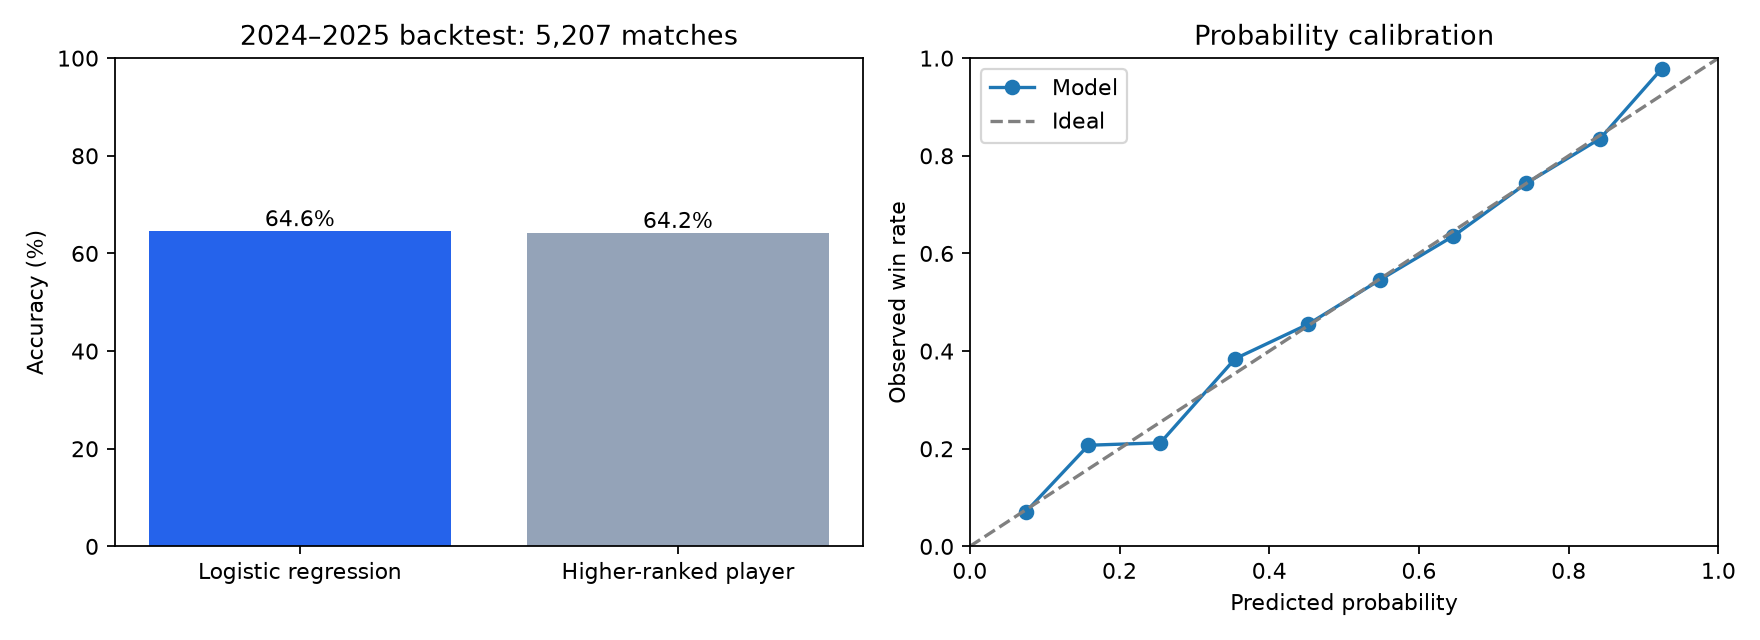

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(metrics.model, metrics.accuracy * 100, color=['#2563eb', '#94a3b8'])
axes[0].set(ylabel='Accuracy (%)', ylim=(0, 100), title=f'2024–2025 backtest: {len(test):,} matches')
for i, value in enumerate(metrics.accuracy):
    axes[0].text(i, value * 100 + 1, f'{value:.1%}', ha='center')
predictions['bin'] = pd.cut(predictions.p_a_wins, np.linspace(0, 1, 11), include_lowest=True)
calibration = predictions.groupby('bin', observed=True).agg(predicted=('p_a_wins', 'mean'), actual=('target', 'mean'), count=('target', 'size'))
axes[1].plot(calibration.predicted, calibration.actual, 'o-', label='Model')
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
axes[1].set(xlabel='Predicted probability', ylabel='Observed win rate', title='Probability calibration', xlim=(0, 1), ylim=(0, 1))
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / 'backtest.png', dpi=160)
if 'get_ipython' in globals():
    plt.show()
else:
    plt.close(fig)


## Interpretation and limitations
- Accuracy is the fraction of matches predicted correctly. Compare both models on the same test matches.
- Log loss and Brier score evaluate probabilities. The ranking baseline emits hard 0/1 probabilities and is principally an accuracy baseline.
- Rankings alone can be difficult to beat. A small improvement may not generalize to other years.
- Dates represent tournament starts. Prior outcomes are withheld for 21 days, sacrificing recency to avoid using same/overlapping-event results.
- Historical results may have corrections and the current database is not a point-in-time archival feed.
- Retirements, walkovers, team events, unknown surfaces and missing rankings are excluded. Results apply to the retained population.
- Training on mirrored examples does not double the number of independent matches. Test matches appear once.
- Historical examples are replayed predictions, not live forecasts. No financial or betting returns are claimed.

## Project explanation
The script converts winner/loser records into neutral Player A/Player B examples. It computes differences in ranking, recent form and surface history. The model learns how those differences relate to winning. A later period evaluates whether it generalizes.

AI assistance was used to write and debug the code and documentation. Review the code, reproduce the results and describe your own contributions accurately.
